# UTS Data Science 2026/2027 — Prediksi Harga Properti di Portugal dengan Regresi
## Notebook Business & Data Understanding (EDA)

Notebook ini mereproduksi seluruh angka, tabel, dan gambar pada **Bab II. Data Understanding** laporan UTS.
Urutan sel mengikuti subbab laporan, sehingga setiap hasil dapat ditelusuri ke bagian laporannya.

**Cara menjalankan**
1. Letakkan `portugal_listinigs.csv` di folder yang sama dengan notebook ini (atau ubah `DATA_PATH` di sel konfigurasi).
2. Pasang dependensi: `pip install pandas numpy matplotlib jupyter`
3. Jalankan semua sel (*Run All*). Gambar disimpan ke folder `figures/`.

> Catatan: dataset diperbarui mingguan oleh pengunggahnya, jadi angka dapat sedikit berbeda bila berkas yang dipakai berbeda dari yang dipakai pada laporan (188.797 baris × 23 kolom).

## 0. Konfigurasi dan impor pustaka

In [3]:
import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

# ---------- Konfigurasi ----------
SEED = 42
DATA_PATH = os.environ.get("DATA_PATH", "portugal_listinigs.csv")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
np.random.seed(SEED)

# Aturan validasi awal (Tabel 2.4) -- bersifat sementara, difinalkan di Data Preparation
PRICE_MIN, PRICE_MAX = 10_000, 10_000_000      # Euro
AREA_MIN, AREA_MAX = 15, 5_000                 # m2
PPM2_MIN, PPM2_MAX = 100, 50_000               # Euro per m2
RESIDENTIAL = ["Apartment", "House"]

# ---------- Gaya grafik ----------
BLUE, ORANGE, LIGHT = "#2a78d6", "#eb6834", "#9bbbe8"
INK, SEC, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": SEC,
    "xtick.color": SEC, "ytick.color": SEC,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlecolor": INK, "axes.titlelocation": "left",
})
euro_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.0f}k" if v < 1e6 else f"{v/1e6:.1f}M")

def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200)
    plt.show()

def style_axes(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, lw=.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

KEY = {}   # menampung angka kunci untuk dicocokkan dengan laporan

## 1. Memuat data (subbab 2.1 dan 2.2)
Satu baris = satu listing. Variabel target: `Price` (harga penawaran, Euro).

In [4]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Ukuran data:", df.shape)
print("Ukuran berkas (MB):", round(os.path.getsize(DATA_PATH) / 1e6, 1))
df.head()

Ukuran data: (189318, 23)
Ukuran berkas (MB): 23.8


,Price,District,City,Town,Type,EnergyCertificate,Floor,NumberOfBathrooms,Parking,TotalArea,...,Garage,Elevator,ElectricCarsCharging,TotalRooms,NumberOfBedrooms,NumberOfWC,ConservationStatus,LivingArea,LotSize,BuiltArea
0,250000.0,Faro,São Brás de Alportel,São Brás de Alportel,Apartment,A+,1st Floor,0.0,1.0,114.0,...,NaN,True,NaN,2.0,NaN,NaN,NaN,114.0,NaN,NaN
1,158000.0,Faro,Portimão,Portimão,Apartment,D,2nd Floor,2.0,1.0,21953.0,...,NaN,True,NaN,1.0,NaN,NaN,NaN,42.0,NaN,48.0
2,19000.0,Faro,Lagoa (Algarve),Estômbar e Parchal,Land,NC,NaN,0.0,0.0,3710.0,...,NaN,False,NaN,NaN,NaN,NaN,NaN,3710.0,NaN,3710.0
3,250000.0,Faro,São Brás de Alportel,São Brás de Alportel,Apartment,A+,1st Floor,2.0,1.0,115.0,...,NaN,True,NaN,2.0,NaN,NaN,NaN,115.0,NaN,NaN
4,2950000.0,Faro,Albufeira,Albufeira e Olhos de Água,Building,NC,NaN,0.0,0.0,265.0,...,NaN,False,NaN,NaN,NaN,NaN,NaN,406.0,NaN,465.0


In [5]:
print(df.dtypes)
KEY["n_rows"], KEY["n_cols"] = df.shape

Price                    float64
District                     str
City                         str
Town                         str
Type                         str
EnergyCertificate            str
Floor                        str
NumberOfBathrooms        float64
Parking                  float64
TotalArea                float64
ConstructionYear         float64
EnergyEfficiencyLevel        str
PublishDate                  str
Garage                    object
Elevator                  object
ElectricCarsCharging      object
TotalRooms               float64
NumberOfBedrooms         float64
NumberOfWC               float64
ConservationStatus           str
LivingArea               float64
LotSize                  float64
BuiltArea                float64
dtype: object


## 2. Data dictionary (subbab 2.3, Tabel 2.2)
Jumlah nilai unik, rentang nilai teramati (data mentah), dan persentase kosong.

In [6]:
rows = []
for c in df.columns:
    s = df[c].dropna()
    r = {"variabel": c, "dtype": str(df[c].dtype), "nilai_unik": s.nunique(),
         "kosong_%": round(df[c].isna().mean() * 100, 1)}
    if pd.api.types.is_numeric_dtype(df[c]):
        r.update(min=s.min(), median=s.median(), max=s.max())
    else:
        r["contoh_teratas"] = ", ".join(map(str, s.value_counts().head(4).index))
    rows.append(r)
data_dict = pd.DataFrame(rows)
data_dict

,variabel,dtype,nilai_unik,kosong_%,min,median,max,contoh_teratas
0,Price,float64,6437,0.2,1.0,240000.0,2.000000e+09,NaN
1,District,str,28,0.0,NaN,NaN,NaN,"Lisboa, Porto, Setúbal, Braga"
2,City,str,282,0.0,NaN,NaN,NaN,"Lisboa, Sintra, Porto, Vila Nova de Gaia"
3,Town,str,2348,0.0,NaN,NaN,NaN,"Paranhos, Cascais e Estoril, Albufeira e Olhos..."
4,Type,str,21,0.0,NaN,NaN,NaN,"Apartment, House, Land, Store"
5,EnergyCertificate,str,12,0.0,NaN,NaN,NaN,"NC, C, D, A"
6,Floor,str,19,85.2,NaN,NaN,NaN,"Ground Floor, 1st Floor, 2nd Floor, 3rd Floor"
7,NumberOfBathrooms,float64,50,9.6,-13.0,1.0,3.020000e+03,NaN
8,Parking,float64,4,0.0,0.0,0.0,3.000000e+00,NaN
9,TotalArea,float64,7638,8.5,-7196067.0,140.0,6.142007e+10,NaN


## 3. Kualitas data

### 3.1 Missing value (subbab 2.4.1, Gambar 2.1 dan Tabel 2.3)

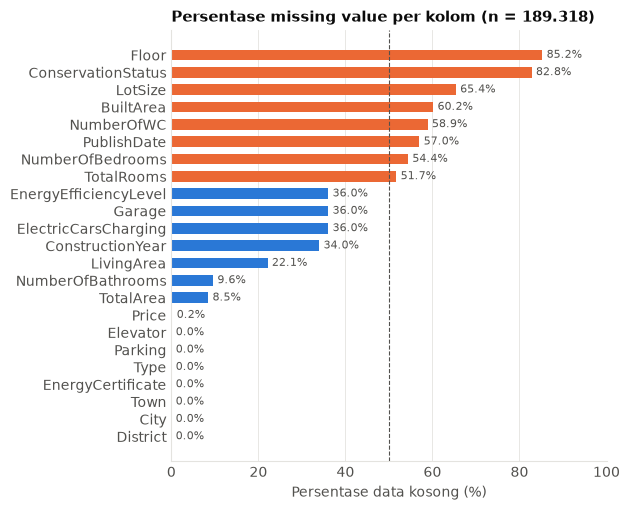

Floor                    85.2
ConservationStatus       82.8
LotSize                  65.4
BuiltArea                60.2
NumberOfWC               58.9
PublishDate              57.0
NumberOfBedrooms         54.4
TotalRooms               51.7
EnergyEfficiencyLevel    36.0
Garage                   36.0
ElectricCarsCharging     36.0
ConstructionYear         34.0
LivingArea               22.1
NumberOfBathrooms         9.6
TotalArea                 8.5
Price                     0.2
Elevator                  0.0
Parking                   0.0
Type                      0.0
EnergyCertificate         0.0
Town                      0.0
District                  0.0
City                      0.0


In [7]:
miss = (df.isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.barh(miss.index, miss.values, color=[ORANGE if v > 50 else BLUE for v in miss.values], height=.62)
for i, v in enumerate(miss.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8, color=SEC)
ax.axvline(50, color=SEC, lw=.8, ls="--")
ax.set_xlim(0, 100)
ax.set_xlabel("Persentase data kosong (%)")
ax.set_title(f"Persentase missing value per kolom (n = {len(df):,})".replace(",", "."))
style_axes(ax, "x")
save("fig2_1_missing.png")
print(miss.sort_values(ascending=False).round(1).to_string())

In [8]:
# Pola kekosongan bersama: Garage, ElectricCarsCharging, EnergyEfficiencyLevel
a, b, c = df.Garage.isna(), df.EnergyEfficiencyLevel.isna(), df.ElectricCarsCharging.isna()
print("Baris kosong serentak pada ketiga kolom :", int((a & b & c).sum()), f"({(a & b & c).mean()*100:.1f}%)")
print("Kolom-kolom itu kosong pada baris yang sama? ", bool((a == b).all() and (a == c).all()))
print("PublishDate kosong pada kelompok tsb.     :", f"{df[a].PublishDate.isna().mean()*100:.1f}%")
print("PublishDate kosong pada baris lainnya     :", f"{df[~a].PublishDate.isna().mean()*100:.1f}%")
print()
print("Komposisi tipe (kelompok kosong vs lainnya):")
print(pd.concat([df[a].Type.value_counts(normalize=True).head(3).round(2).rename("kosong"),
                 df[~a].Type.value_counts(normalize=True).head(3).round(2).rename("terisi")], axis=1))
KEY["n_triple_missing"] = int((a & b & c).sum())
KEY["price_missing"] = int(df.Price.isna().sum())

Baris kosong serentak pada ketiga kolom : 68247 (36.0%)
Kolom-kolom itu kosong pada baris yang sama?  True
PublishDate kosong pada kelompok tsb.     : 100.0%
PublishDate kosong pada baris lainnya     : 32.8%

Komposisi tipe (kelompok kosong vs lainnya):
           kosong  terisi
Type                     
Apartment    0.35    0.38
House        0.27    0.27
Land         0.23    0.21


In [9]:
# Tabel 2.3: persentase kosong menurut tipe properti
cols = ["LotSize", "Floor", "NumberOfBedrooms", "ConstructionYear", "ConservationStatus", "TotalArea"]
tab_2_3 = (df[df.Type.isin(["Apartment", "House", "Land"])]
           .groupby("Type")[cols].apply(lambda g: g.isna().mean() * 100).round(0).T)
tab_2_3

Type,Apartment,House,Land
LotSize,89.0,52.0,38.0
Floor,66.0,98.0,100.0
NumberOfBedrooms,34.0,36.0,93.0
ConstructionYear,21.0,6.0,87.0
ConservationStatus,76.0,80.0,97.0
TotalArea,0.0,0.0,38.0


### 3.2 Duplikasi (subbab 2.4.2)

In [10]:
dup_full = int(df.duplicated().sum())
key_cols = ["Price", "District", "City", "Town", "Type", "TotalArea", "NumberOfBedrooms", "ConstructionYear"]
dup_key_extra = int(df.drop_duplicates().duplicated(subset=key_cols).sum())
print(f"Duplikat penuh                       : {dup_full:,} ({dup_full/len(df)*100:.1f}%)".replace(",", "."))
print(f"Kandidat duplikat tambahan (kunci)   : {dup_key_extra:,}".replace(",", "."))
KEY["dup_full"], KEY["dup_key_extra"] = dup_full, dup_key_extra

Duplikat penuh                       : 11.387 (6.0%)
Kandidat duplikat tambahan (kunci)   : 15.494


### 3.3 Outlier dan nilai tidak wajar (subbab 2.4.3, Gambar 2.2 dan Tabel 2.4)

In [11]:
p = df["Price"].dropna()
q1, q3 = p.quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
price_stats = {
    "n": int(p.size), "mean": p.mean(), "median": p.median(), "Q1": q1, "Q3": q3,
    "P1": p.quantile(.01), "P99": p.quantile(.99), "max": p.max(),
    "skew_raw": p.skew(), "skew_log1p": np.log1p(p).skew(),
    "pagar_atas_IQR": fence, "n_di_atas_pagar": int((p > fence).sum()),
    "pct_di_atas_pagar": round((p > fence).mean() * 100, 1),
    "n_<1000": int((p < 1000).sum()), "n_<10000": int((p < 10_000).sum()), "n_>10jt": int((p > 1e7).sum()),
}
pd.Series(price_stats)

n                    1.888570e+05
mean                 4.012413e+05
median               2.400000e+05
Q1                   9.500000e+04
Q3                   4.250000e+05
P1                   5.800000e+03
P99                  2.850000e+06
max                  2.000000e+09
skew_raw             3.155631e+02
skew_log1p          -5.880725e-01
pagar_atas_IQR       9.200000e+05
n_di_atas_pagar      1.429600e+04
pct_di_atas_pagar    7.600000e+00
n_<1000              5.400000e+01
n_<10000             3.551000e+03
n_>10jt              8.000000e+01
dtype: float64

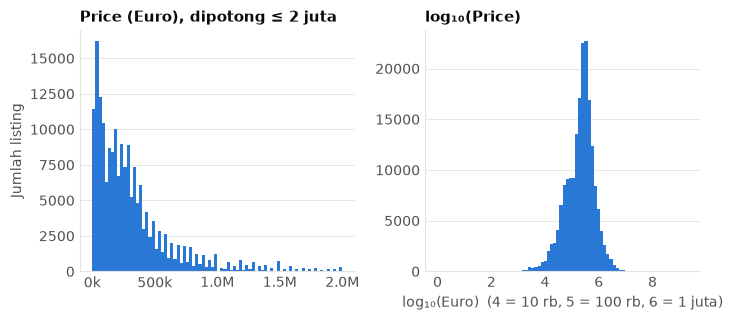

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.3))
axs[0].hist(p[p <= 2e6], bins=80, color=BLUE)
axs[0].set_title("Price (Euro), dipotong ≤ 2 juta")
axs[0].xaxis.set_major_formatter(euro_fmt)
axs[0].set_ylabel("Jumlah listing")
axs[1].hist(np.log10(p[p > 0]), bins=80, color=BLUE)
axs[1].set_title("log₁₀(Price)")
axs[1].set_xlabel("log₁₀(Euro)  (4 = 10 rb, 5 = 100 rb, 6 = 1 juta)")
for ax in axs: style_axes(ax, "y")
save("fig2_2_price_hist.png")

In [13]:
# Nilai mustahil pada variabel ukuran dan jumlah
extreme = {
    "TotalArea <= 0": int((df.TotalArea <= 0).sum()),
    "TotalArea < 0": int((df.TotalArea < 0).sum()),
    "TotalArea > 100.000 m2": int((df.TotalArea > 1e5).sum()),
    "TotalArea maksimum": df.TotalArea.max(),
    "NumberOfBathrooms > 10": int((df.NumberOfBathrooms > 10).sum()),
    "NumberOfBathrooms maksimum": df.NumberOfBathrooms.max(),
    "TotalRooms > 30": int((df.TotalRooms > 30).sum()),
    "TotalRooms maksimum": df.TotalRooms.max(),
    "NumberOfBedrooms > 15": int((df.NumberOfBedrooms > 15).sum()),
}
pd.Series(extreme)

TotalArea <= 0                1.030000e+03
TotalArea < 0                 8.000000e+00
TotalArea > 100.000 m2        7.670000e+02
TotalArea maksimum            6.142007e+10
NumberOfBathrooms > 10        2.970000e+02
NumberOfBathrooms maksimum    3.020000e+03
TotalRooms > 30               8.800000e+01
TotalRooms maksimum           2.751000e+03
NumberOfBedrooms > 15         1.530000e+02
dtype: float64

In [14]:
# Tabel 2.4: aturan validasi awal pada subset Apartment dan House (berurutan)
res = df[df.Type.isin(RESIDENTIAL)].copy()
log = [("0. Subset awal Apartment dan House", len(res), len(res))]

n = len(res); res = res.drop_duplicates()
log.append(("1. Hapus duplikat penuh", n - len(res), len(res)))

n = len(res); res = res[res.Price.between(PRICE_MIN, PRICE_MAX)]
log.append((f"2. Harga kosong / di luar {PRICE_MIN:,}-{PRICE_MAX:,} EUR".replace(",", "."), n - len(res), len(res)))

n = len(res); res = res[res.TotalArea.between(AREA_MIN, AREA_MAX)]
log.append((f"3. Luas kosong / di luar {AREA_MIN}-{AREA_MAX} m2", n - len(res), len(res)))

res["ppm2"] = res.Price / res.TotalArea
n = len(res); res = res[res.ppm2.between(PPM2_MIN, PPM2_MAX)]
log.append((f"4. Harga per m2 di luar {PPM2_MIN}-{PPM2_MAX}", n - len(res), len(res)))

rules = pd.DataFrame(log, columns=["aturan", "baris_terdampak", "sisa_baris"])
print(rules.to_string(index=False))
print(f"\nSubset akhir: {len(res):,} baris = {len(res)/log[0][1]*100:.1f}% dari subset awal".replace(",", "."))
res["logp"], res["loga"] = np.log(res.Price), np.log(res.TotalArea)
KEY["n_res_raw"], KEY["n_res_clean"] = log[0][1], len(res)

                                         aturan  baris_terdampak  sisa_baris
             0. Subset awal Apartment dan House           121488      121488
                        1. Hapus duplikat penuh             6831      114657
2. Harga kosong / di luar 10.000-10.000.000 EUR             1100      113557
            3. Luas kosong / di luar 15-5000 m2             1757      111800
              4. Harga per m2 di luar 100-50000             1687      110113

Subset akhir: 110.113 baris = 90.6% dari subset awal


### 3.4 Inkonsistensi format (subbab 2.4.4)

In [15]:
print("EnergyCertificate:", df.EnergyCertificate.value_counts().to_dict())
print("\nEnergyEfficiencyLevel:", df.EnergyEfficiencyLevel.value_counts().to_dict())
print("\nFloor (", df.Floor.nunique(), "kategori ):", df.Floor.value_counts().to_dict())
print("\nType (", df.Type.nunique(), "kategori ):", df.Type.value_counts().to_dict())
print("\nDistrict dengan label khusus:")
print(df.District.value_counts()[lambda s: s.index.str.startswith(("Z -", "Ilha"))])

# PublishDate: format tidak seragam -> penguraian 'mixed'
pub = pd.to_datetime(df.PublishDate, errors="coerce", format="mixed")
print("\nPublishDate terurai:", int(pub.notna().sum()), f"({pub.notna().mean()*100:.1f}%)",
      "| rentang:", pub.min(), "->", pub.max())
print("Per tahun:", pub.dt.year.value_counts().sort_index().astype(int).to_dict())
share_2426 = pub.dt.year.isin([2024, 2025, 2026]).sum() / pub.notna().sum()
print(f"Proporsi bertanggal yang berasal dari 2024-2026: {share_2426*100:.1f}%")

EnergyCertificate: {'NC': 81990, 'C': 23416, 'D': 22207, 'A': 15607, 'E': 15141, 'F': 10266, 'A+': 7535, 'B-': 6483, 'B': 6047, 'G': 549, 'No Certificate': 45, 'Not available': 18}

EnergyEfficiencyLevel: {'NC': 51919, 'C': 14861, 'D': 13998, 'A': 10700, 'E': 9420, 'F': 6396, 'A+': 5402, 'B-': 4170, 'B': 3856, 'G': 305, 'No Certificate': 44}

Floor ( 19 kategori ): {'Ground Floor': 6973, '1st Floor': 6038, '2nd Floor': 5019, '3rd Floor': 3817, '4th Floor': 1902, '5th Floor': 1154, 'Basement Level': 750, '6th Floor': 655, '7th Floor': 425, 'Above 10th Floor': 314, '8th Floor': 314, '9th Floor': 167, 'Duplex': 165, 'Top Floor': 91, 'Basement': 89, 'Triplex': 28, 'Service Floor': 14, 'Attic': 10, 'Mezzanine': 4}

Type ( 21 kategori ): {'Apartment': 69973, 'House': 51515, 'Land': 41669, 'Store': 6908, 'Farm': 5053, 'Building': 3385, 'Transfer of lease': 2437, 'Warehouse': 1977, 'Garage': 1375, 'Other - Commercial': 1074, 'Office': 906, 'Other - Residential': 837, 'Duplex': 569, 'Industrial

## 4. Eksplorasi data (subbab 2.5)
Kecuali dinyatakan lain, analisis memakai subset Apartment dan House yang sudah divalidasi (`res`).

### 4.1 Komposisi tipe properti (Gambar 2.3)

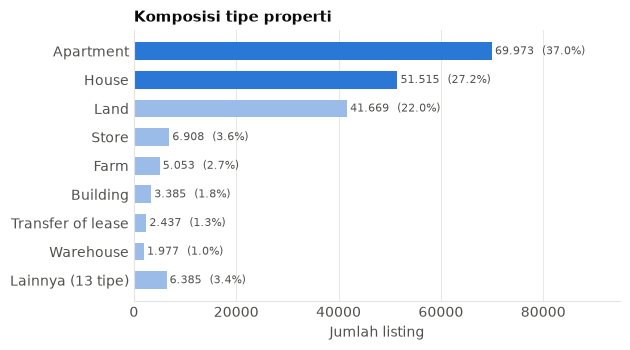

Hunian (Apartment+House): 121488 (64.2%)
Land: NC sertifikat 99.3%

               n  median_harga  median_luas  median_ppm2
Type                                                    
Apartment  64227      300000.0         99.0       3276.0
House      45886      290000.0        181.0       1569.0


In [16]:
tc = df.Type.value_counts()
top, other = tc.head(8), tc.iloc[8:].sum()
s = pd.concat([top, pd.Series({f"Lainnya ({len(tc) - 8} tipe)": other})])[::-1]

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.barh(s.index, s.values, color=[BLUE if k in RESIDENTIAL else LIGHT for k in s.index], height=.62)
for i, v in enumerate(s.values):
    ax.text(v + 600, i, f"{v:,.0f}".replace(",", ".") + f"  ({v/len(df)*100:.1f}%)", va="center", fontsize=8, color=SEC)
ax.set_xlim(0, 95000)
ax.set_xlabel("Jumlah listing")
ax.set_title("Komposisi tipe properti")
style_axes(ax, "x")
save("fig2_3_type.png")

print("Hunian (Apartment+House):", int(tc[RESIDENTIAL].sum()), f"({tc[RESIDENTIAL].sum()/len(df)*100:.1f}%)")
print("Land: NC sertifikat", f"{(df[df.Type=='Land'].EnergyCertificate=='NC').mean()*100:.1f}%")
print()
print(res.groupby("Type").agg(n=("Price", "size"), median_harga=("Price", "median"),
                              median_luas=("TotalArea", "median"), median_ppm2=("ppm2", "median")).round(0))

### 4.2 Distribusi geografis dan harga (Gambar 2.4)

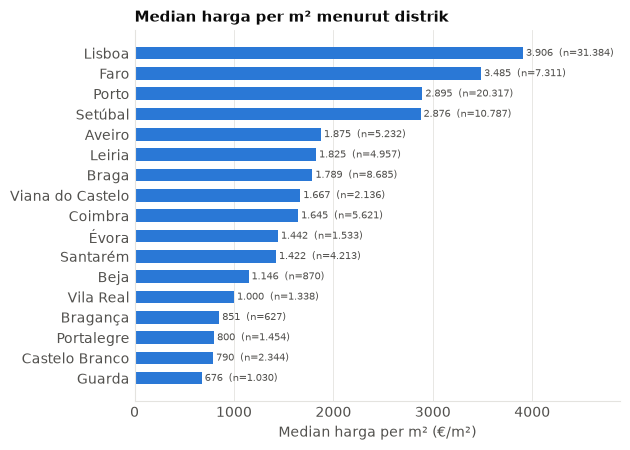

                      n  median_harga  median_ppm2
District                                          
Lisboa            31384      425000.0       3906.0
Faro               7311      385000.0       3485.0
Porto             20317      316900.0       2895.0
Setúbal           10787      331000.0       2876.0
Aveiro             5232      257950.0       1875.0
Leiria             4957      248000.0       1825.0
Braga              8685      259900.0       1789.0
Viana do Castelo   2136      200140.0       1667.0
Coimbra            5621      195000.0       1645.0
Évora              1533      180000.0       1442.0
Santarém           4213      180000.0       1422.0
Beja                870      148000.0       1146.0
Vila Real          1338      145000.0       1000.0
Bragança            627      125000.0        851.0
Portalegre         1454       89000.0        800.0
Castelo Branco     2344       90000.0        790.0
Guarda             1030       79250.0        676.0

Rasio Lisboa/Guarda: harga per

In [17]:
g = res.groupby("District").agg(n=("Price", "size"), median_harga=("Price", "median"), median_ppm2=("ppm2", "median"))
g = g[g.n >= 200].sort_values("median_ppm2")

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.barh(g.index, g.median_ppm2, color=BLUE, height=.62)
for i, (v, n_) in enumerate(zip(g.median_ppm2, g.n)):
    ax.text(v + 30, i, f"{v:,.0f}".replace(",", ".") + f"  (n={n_:,})".replace(",", "."), va="center", fontsize=7.5, color=SEC)
ax.set_xlim(0, g.median_ppm2.max() * 1.25)
ax.set_xlabel("Median harga per m² (€/m²)")
ax.set_title("Median harga per m² menurut distrik")
style_axes(ax, "x")
save("fig2_4_district.png")

print(g.sort_values("median_ppm2", ascending=False).round(0).to_string())
print("\nRasio Lisboa/Guarda: harga per m2 =", round(g.loc["Lisboa", "median_ppm2"] / g.loc["Guarda", "median_ppm2"], 1),
      "| median harga =", round(g.loc["Lisboa", "median_harga"] / g.loc["Guarda", "median_harga"], 1))

### 4.3 Sertifikat energi (Gambar 2.5)

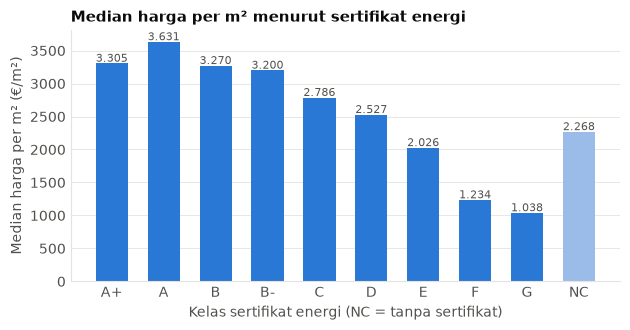

        n  median_harga  median_ppm2
EC                                  
A+   6432      455500.0       3305.0
A   13597      455000.0       3631.0
B    4588      449770.0       3270.0
B-   4197      420000.0       3200.0
C   17185      305000.0       2786.0
D   18699      269000.0       2527.0
E   12622      235000.0       2026.0
F    7911      165000.0       1234.0
G     252      139950.0       1038.0
NC  24630      260000.0       2268.0

NC pada subset hunian : 22.4%
NC pada seluruh data  : 43.3%


In [18]:
order = ["A+", "A", "B", "B-", "C", "D", "E", "F", "G", "NC"]
res["EC"] = res.EnergyCertificate.replace({"No Certificate": "NC", "Not available": "NC"})
e = res.groupby("EC").agg(n=("Price", "size"), median_harga=("Price", "median"), median_ppm2=("ppm2", "median")).reindex(order)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(e.index, e.median_ppm2, color=[BLUE] * 9 + [LIGHT], width=.62)
for i, v in enumerate(e.median_ppm2):
    ax.text(i, v + 25, f"{v:,.0f}".replace(",", "."), ha="center", fontsize=8, color=SEC)
ax.set_ylabel("Median harga per m² (€/m²)")
ax.set_xlabel("Kelas sertifikat energi (NC = tanpa sertifikat)")
ax.set_title("Median harga per m² menurut sertifikat energi")
style_axes(ax, "y")
save("fig2_5_energy.png")

print(e.round(0))
print(f"\nNC pada subset hunian : {(res.EC=='NC').mean()*100:.1f}%")
print(f"NC pada seluruh data  : {(df.EnergyCertificate=='NC').mean()*100:.1f}%")

### 4.4 Korelasi dan hubungan fitur-target (Gambar 2.6 dan 2.7)

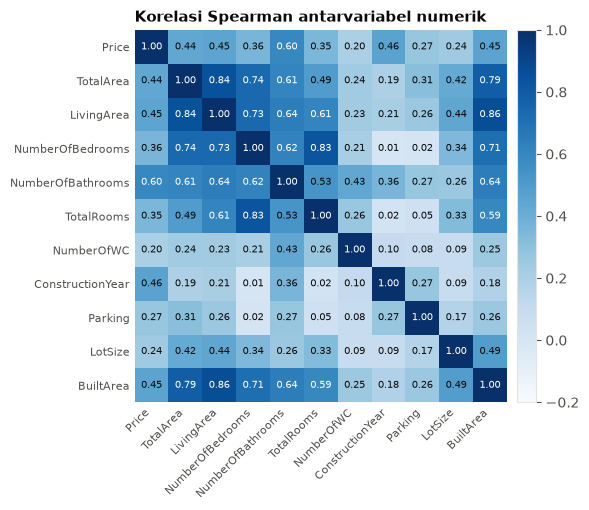

Price                1.00
NumberOfBathrooms    0.60
ConstructionYear     0.46
BuiltArea            0.45
LivingArea           0.45
TotalArea            0.44
NumberOfBedrooms     0.36
TotalRooms           0.35
Parking              0.27
LotSize              0.24
NumberOfWC           0.20


In [19]:
nums = ["Price", "TotalArea", "LivingArea", "NumberOfBedrooms", "NumberOfBathrooms", "TotalRooms",
        "NumberOfWC", "ConstructionYear", "Parking", "LotSize", "BuiltArea"]
corr = res[nums].corr(method="spearman")   # pairwise complete

fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr.values, cmap="Blues", vmin=-0.2, vmax=1)
ax.set_xticks(range(len(nums))); ax.set_xticklabels(nums, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(nums))); ax.set_yticklabels(nums, fontsize=8)
for i in range(len(nums)):
    for j in range(len(nums)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > .55 else INK)
ax.set_title("Korelasi Spearman antarvariabel numerik")
ax.spines[:].set_visible(False); ax.tick_params(length=0)
fig.colorbar(im, fraction=.04, pad=.02)
save("fig2_6_corr.png")
print(corr["Price"].round(2).sort_values(ascending=False).to_string())

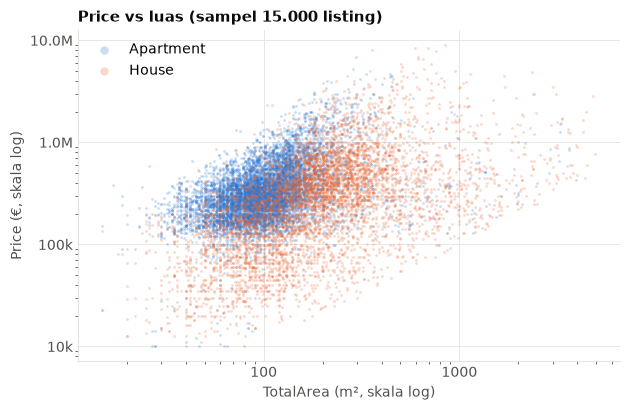

Korelasi Pearson log-log (Price vs TotalArea): 0.4


In [20]:
sm = res.sample(15_000, random_state=SEED)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for t, col in [("Apartment", BLUE), ("House", ORANGE)]:
    d_ = sm[sm.Type == t]
    ax.scatter(d_.TotalArea, d_.Price, s=4, alpha=.25, color=col, lw=0, label=t)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("TotalArea (m², skala log)"); ax.set_ylabel("Price (€, skala log)")
ax.set_title("Price vs luas (sampel 15.000 listing)")
ax.legend(frameon=False, markerscale=3, loc="upper left")
ax.grid(color=GRID, lw=.6); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.yaxis.set_major_formatter(euro_fmt)
save("fig2_7_scatter.png")
print("Korelasi Pearson log-log (Price vs TotalArea):", round(np.corrcoef(res.loga, res.logp)[0, 1], 2))

### 4.5 Usia, kondisi, dan fasilitas (Tabel 2.5)

In [21]:
def med(df_, by):
    return df_.groupby(by)["ppm2"].agg(median_ppm2="median", n="size").round(0)

cons_order = ["Needs renovation", "Reasonable", "Used", "Good condition", "Like new", "New"]
print("Kondisi (ConservationStatus)"); print(med(res, "ConservationStatus").reindex(cons_order), "\n")

cs = res.dropna(subset=["ConstructionYear"]).copy()
bins = [1899, 1919, 1939, 1959, 1979, 1999, 2019, 2026]
labels = ["1900-1919", "1920-1939", "1940-1959", "1960-1979", "1980-1999", "2000-2019", "2020-2026"]
cs["periode"] = pd.cut(cs.ConstructionYear, bins=bins, labels=labels)
print("Periode konstruksi"); print(med(cs, "periode"), "\n")

apt = res[res.Type == "Apartment"]
print("Elevator (Apartment)"); print(med(apt.dropna(subset=["Elevator"]), "Elevator"), "\n")
print("Garage (Apartment, yang tercatat)"); print(med(apt.dropna(subset=["Garage"]), "Garage"))

Kondisi (ConservationStatus)
                    median_ppm2     n
ConservationStatus                   
Needs renovation         1132.0  1953
Reasonable               1909.0   873
Used                     2424.0  2668
Good condition           2821.0  6975
Like new                 3393.0  3474
New                      3812.0  9121 

Periode konstruksi
           median_ppm2      n
periode                      
1900-1919       3957.0    169
1920-1939        917.0   5789
1940-1959       1592.0   8700
1960-1979       2311.0  11651
1980-1999       2283.0  25957
2000-2019       2320.0  22049
2020-2026       3495.0  20358 

Elevator (Apartment)
          median_ppm2      n
Elevator                    
False          2946.0  23036
True           3438.0  41191 

Garage (Apartment, yang tercatat)
        median_ppm2      n
Garage                    
False        3717.0  36020
True         2833.0   7217


## 5. Representativitas dan bias sampel (subbab 2.6, Tabel 2.6)

In [22]:
dist = df.District.value_counts()
share = (dist / len(df) * 100).round(1)
islands = dist[dist.index.str.startswith("Ilha")]

print("Lisboa :", f"{share['Lisboa']}%", "| Porto :", f"{share['Porto']}%")
print("Lisboa + Porto :", f"{dist[['Lisboa','Porto']].sum()/len(df)*100:.1f}%")
print("Lima distrik teratas :", f"{dist.head(5).sum()/len(df)*100:.1f}%")
print("Viseu :", int(dist['Viseu']), f"({dist['Viseu']/len(df)*100:.2f}%)")
print("Kepulauan (9 wilayah) :", int(islands.sum()), f"({islands.sum()/len(df)*100:.2f}%) dari", len(islands), "wilayah")
print("Non-hunian :", f"{(~df.Type.isin(RESIDENTIAL)).mean()*100:.1f}%", "| Land :", f"{(df.Type=='Land').mean()*100:.1f}%")
print("PublishDate terisi :", f"{pub.notna().mean()*100:.1f}%", "| bertanggal 2024-2026 :", f"{share_2426*100:.1f}%")
print()
print("Distribusi 10 distrik teratas:")
print(pd.DataFrame({"listing": dist.head(10), "persen": share.head(10)}))

Lisboa : 24.0% | Porto : 16.9%
Lisboa + Porto : 40.9%
Lima distrik teratas : 64.4%
Viseu : 73 (0.04%)
Kepulauan (9 wilayah) : 492 (0.26%) dari 9 wilayah
Non-hunian : 35.8% | Land : 22.0%
PublishDate terisi : 43.0% | bertanggal 2024-2026 : 98.0%

Distribusi 10 distrik teratas:
                listing  persen
District                       
Lisboa            45342    24.0
Porto             32056    16.9
Setúbal           16650     8.8
Braga             15529     8.2
Faro              12430     6.6
Coimbra           10660     5.6
Aveiro            10419     5.5
Leiria            10070     5.3
Santarém           9885     5.2
Castelo Branco     6533     3.5


## 6. Ringkasan angka kunci
Bandingkan dengan angka pada laporan (sel ini hanya mencetak, tidak menguji).

In [23]:
summary = {
    "Baris x kolom": f"{KEY['n_rows']:,} x {KEY['n_cols']}".replace(",", "."),
    "Price kosong": KEY["price_missing"],
    "Baris kosong serentak (Garage/ElectricCarsCharging/EnergyEfficiencyLevel)": KEY["n_triple_missing"],
    "Duplikat penuh": KEY["dup_full"],
    "Kandidat duplikat tambahan": KEY["dup_key_extra"],
    "Subset hunian mentah": KEY["n_res_raw"],
    "Subset hunian setelah validasi": KEY["n_res_clean"],
    "Median / Q1 / Q3 Price": f"{price_stats['median']:,.0f} / {price_stats['Q1']:,.0f} / {price_stats['Q3']:,.0f}".replace(",", "."),
    "P1 / P99 Price": f"{price_stats['P1']:,.0f} / {price_stats['P99']:,.0f}".replace(",", "."),
    "Skewness raw -> log1p": f"{price_stats['skew_raw']:.0f} -> {price_stats['skew_log1p']:.2f}",
}
pd.Series(summary)

Baris x kolom                                                                              189.318 x 23
Price kosong                                                                                        461
Baris kosong serentak (Garage/ElectricCarsCharging/EnergyEfficiencyLevel)                         68247
Duplikat penuh                                                                                    11387
Kandidat duplikat tambahan                                                                        15494
Subset hunian mentah                                                                             121488
Subset hunian setelah validasi                                                                   110113
Median / Q1 / Q3 Price                                                       240.000 / 95.000 / 425.000
P1 / P99 Price                                                                        5.800 / 2.850.000
Skewness raw -> log1p                                           

In [24]:
print("Gambar yang dihasilkan:")
for f in sorted(os.listdir(FIG_DIR)):
    print(" -", os.path.join(FIG_DIR, f))

Gambar yang dihasilkan:
 - figures/fig2_1_missing.png
 - figures/fig2_2_price_hist.png
 - figures/fig2_3_type.png
 - figures/fig2_4_district.png
 - figures/fig2_5_energy.png
 - figures/fig2_6_corr.png
 - figures/fig2_7_scatter.png
